# IDHM por Unidade da Federação (1991–2024)

Análise da `Tabela4.csv` (IDHM — Índice de Desenvolvimento Humano Municipal, por UF) com **pandas** e gráficos de linhas com **matplotlib**.

Roteiro:
1. Abrir um CSV com `;` e vírgula decimal
2. Limpar colunas vazias
3. Ordenar os estados por maior IDH em 2024
4. Qual estado teve a maior melhora de IDH entre 1991 e 2024?
5. Existe algum estado em que o IDH piorou?
6. Passar a tabela do formato largo para o formato longo (`melt`)
7. Plotar apenas Minas Gerais
8. Plotar a evolução do IDH de cada estado

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Abrir o CSV com `;` e vírgula decimal

Detalhes do arquivo:
- separador `;` e decimal `,` (padrão do Excel em português);
- codificação **latin-1** (com UTF-8 os acentos de *Acre*, *Ceará*, *São Paulo* viram `�`);
- a 1ª linha é só o título — o cabeçalho real está na 2ª, por isso `skiprows=1`.

In [2]:
df = pd.read_csv('Tabela4.csv', sep=';', decimal=',', encoding='latin-1', skiprows=1)
df.head()

,Sigla,Código,Estado,1991,2000,2010,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,AC,12,Acre,0.402,0.517,0.663,0.705,0.709,0.719,0.719,0.723,0.711,0.731,0.738,0.736,0.702,0.732,0.740,0.754
1,AL,27,Alagoas,0.370,0.471,0.631,0.657,0.653,0.670,0.669,0.680,0.682,0.694,0.693,0.694,0.691,0.722,0.739,0.746
2,AM,13,Amazonas,0.430,0.515,0.674,0.706,0.717,0.720,0.724,0.723,0.743,0.732,0.739,0.725,0.700,0.757,0.764,0.767
3,AP,16,Amapá,0.472,0.577,0.708,0.709,0.735,0.726,0.728,0.732,0.731,0.737,0.732,0.707,0.681,0.743,0.767,0.759
4,BA,29,Bahia,0.386,0.512,0.660,0.684,0.686,0.700,0.708,0.708,0.715,0.714,0.723,0.726,0.698,0.734,0.740,0.759


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 19 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Sigla   27 non-null     str    
 1   Código  27 non-null     int64  
 2   Estado  27 non-null     str    
 3   1991    27 non-null     float64
 4   2000    27 non-null     float64
 5   2010    27 non-null     float64
 6   2012    27 non-null     float64
 7   2013    27 non-null     float64
 8   2014    27 non-null     float64
 9   2015    27 non-null     float64
 10  2016    27 non-null     float64
 11  2017    27 non-null     float64
 12  2018    27 non-null     float64
 13  2019    27 non-null     float64
 14  2020    27 non-null     float64
 15  2021    27 non-null     float64
 16  2022    27 non-null     float64
 17  2023    27 non-null     float64
 18  2024    27 non-null     float64
dtypes: float64(16), int64(1), str(2)
memory usage: 4.1 KB


## 2. Limpar colunas vazias

Removemos colunas totalmente vazias (sobras de `;;;` no fim das linhas, que o pandas lê como `Unnamed: ...`) e linhas vazias.

In [4]:
print('Antes:', df.shape)

df = df.dropna(axis=1, how='all')                                    # colunas 100% vazias
df = df.loc[:, ~df.columns.astype(str).str.startswith('Unnamed')]    # colunas sem nome
df = df.dropna(axis=0, how='all')                                    # linhas 100% vazias
df['Estado'] = df['Estado'].str.strip()

print('Depois:', df.shape)
df.columns.tolist()

Antes: (27, 19)
Depois: (27, 19)


['Sigla',
 'Código',
 'Estado',
 '1991',
 '2000',
 '2010',
 '2012',
 '2013',
 '2014',
 '2015',
 '2016',
 '2017',
 '2018',
 '2019',
 '2020',
 '2021',
 '2022',
 '2023',
 '2024']

## 3. Estados ordenados pelo maior IDH em 2024

In [5]:
ranking_2024 = (
    df[['Sigla', 'Estado', '2024']]
    .sort_values('2024', ascending=False)
    .reset_index(drop=True)
)
ranking_2024.index = ranking_2024.index + 1   # posição começando em 1
ranking_2024

,Sigla,Estado,2024
1,DF,Distrito Federal,0.866
2,SP,São Paulo,0.838
3,SC,Santa Catarina,0.833
4,PR,Paraná,0.822
5,RJ,Rio de Janeiro,0.819
6,RS,Rio Grande do Sul,0.818
7,GO,Goiás,0.815
8,MT,Mato Grosso,0.812
9,MG,Minas Gerais,0.809
10,ES,Espírito Santo,0.804


## 4. Maior melhora de IDH entre 1991 e 2024

In [6]:
df['Melhora_1991_2024'] = np.round(df['2024'] - df['1991'], 3)
df['Melhora_%'] = np.round((df['2024'] - df['1991']) / df['1991'] * 100, 1)

melhora = (
    df[['Sigla', 'Estado', '1991', '2024', 'Melhora_1991_2024', 'Melhora_%']]
    .sort_values('Melhora_1991_2024', ascending=False)
    .reset_index(drop=True)
)
melhora

,Sigla,Estado,1991,2024,Melhora_1991_2024,Melhora_%
0,TO,Tocantins,0.369,0.797,0.428,116.0
1,PI,Piauí,0.362,0.764,0.402,111.0
2,MA,Maranhão,0.357,0.745,0.388,108.7
3,RO,Rondônia,0.407,0.786,0.379,93.1
4,PB,Paraíba,0.382,0.760,0.378,99.0
5,AL,Alagoas,0.370,0.746,0.376,101.6
6,BA,Bahia,0.386,0.759,0.373,96.6
7,CE,Ceará,0.405,0.773,0.368,90.9
8,MT,Mato Grosso,0.449,0.812,0.363,80.8
9,SE,Sergipe,0.408,0.761,0.353,86.5


In [7]:
campeao = melhora.iloc[0]
print(f"Maior melhora: {campeao['Estado']} ({campeao['Sigla']}) — "
      f"de {campeao['1991']:.3f} em 1991 para {campeao['2024']:.3f} em 2024 "
      f"(+{campeao['Melhora_1991_2024']:.3f}, +{campeao['Melhora_%']}%)")

Maior melhora: Tocantins (TO) — de 0.369 em 1991 para 0.797 em 2024 (+0.428, +116.0%)


## 5. Existe algum estado em que o IDH piorou?

Olhamos de três jeitos:
- **1991 → 2024** (período inteiro);
- **ano a ano**, para achar quedas pontuais;
- **2023 → 2024** (último ano).

In [8]:
pioraram_periodo = df[df['Melhora_1991_2024'] < 0]
print('Estados com IDH menor em 2024 do que em 1991:', len(pioraram_periodo))

Estados com IDH menor em 2024 do que em 1991: 0


In [9]:
anos = [c for c in df.columns if str(c).isdigit()]

# Diferença entre cada ano e o ano anterior disponível
variacao = df.set_index('Sigla')[anos].diff(axis=1)

quedas_por_ano = (variacao < 0).sum()
quedas_por_ano.name = 'Estados com queda'
quedas_por_ano.to_frame().T

,1991,2000,2010,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
Estados com queda,0,0,0,1,5,1,7,8,5,3,5,20,27,0,0,2


In [10]:
ultimo_ano = variacao['2024']
pioraram_2024 = ultimo_ano[ultimo_ano < 0].sort_values()
print('Estados com IDH menor em 2024 do que em 2023:')
pioraram_2024

Estados com IDH menor em 2024 do que em 2023:


Sigla
AP   -0.008
DF   -0.004
Name: 2024, dtype: float64

## 6. Do formato largo para o formato longo (`melt`)

In [11]:
df_largo = df.drop(columns=['Melhora_1991_2024', 'Melhora_%'])

anos = [c for c in df_largo.columns if str(c).isdigit()]
print(anos)

id_vars = [c for c in df_largo.columns if c not in anos]
df_longo = df_largo.melt(
    id_vars=id_vars,
    value_vars=anos,
    var_name='Ano',
    value_name='IDH',
)
df_longo['Ano'] = df_longo['Ano'].astype(int)
df_longo['IDH'] = pd.to_numeric(df_longo['IDH'], errors='coerce')
df_longo.head()

['1991', '2000', '2010', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024']


,Sigla,Código,Estado,Ano,IDH
0,AC,12,Acre,1991,0.402
1,AL,27,Alagoas,1991,0.370
2,AM,13,Amazonas,1991,0.430
3,AP,16,Amapá,1991,0.472
4,BA,29,Bahia,1991,0.386


In [12]:
print('Formato largo:', df_largo.shape, '→ formato longo:', df_longo.shape)
print('27 estados ×', len(anos), 'anos =', 27 * len(anos), 'linhas')

Formato largo: (27, 19) → formato longo: (432, 5)
27 estados × 16 anos = 432 linhas


## 7. Apenas Minas Gerais

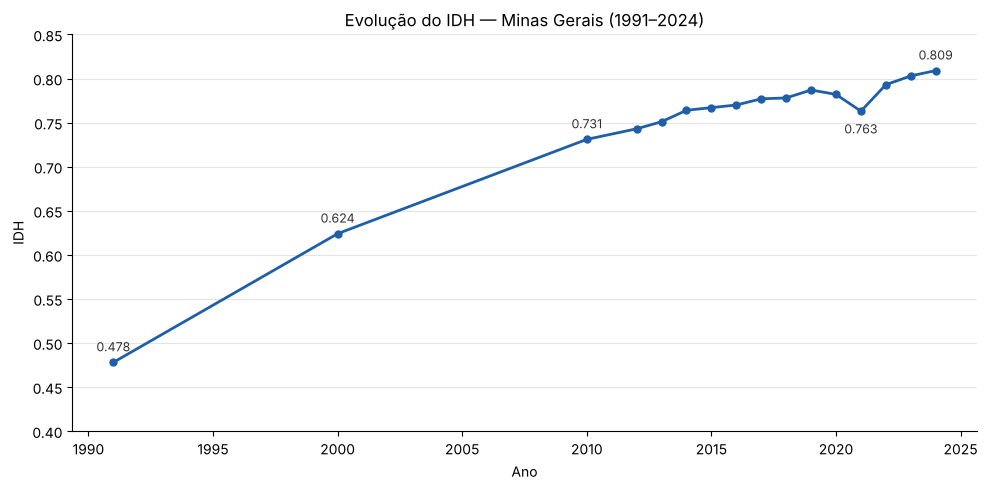

In [13]:
mg = df_longo[df_longo['Sigla'] == 'MG'].sort_values('Ano')

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(mg['Ano'], mg['IDH'], marker='o', markersize=5, linewidth=2, color='#1f5fa8')

# Rótulos só no início, no ponto mais baixo recente e no fim
for ano in [1991, 2000, 2010, 2021, 2024]:
    valor = mg.loc[mg['Ano'] == ano, 'IDH'].iloc[0]
    ax.annotate(f'{valor:.3f}', (ano, valor), textcoords='offset points',
                xytext=(0, -16 if ano == 2021 else 8), ha='center', fontsize=9, color='#333333')

ax.set_title('Evolução do IDH — Minas Gerais (1991–2024)')
ax.set_xlabel('Ano')
ax.set_ylabel('IDH')
ax.set_ylim(0.4, 0.85)
ax.grid(axis='y', color='#e5e5e5')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig('idh_minas_gerais.png', dpi=150)
plt.show()

> Repare que os anos **não são igualmente espaçados** (1991, 2000, 2010 e depois anual). Como o eixo X é numérico, o matplotlib respeita a distância real entre os anos.
>
> A queda em **2021** acontece em todos os 27 estados — provavelmente efeito da pandemia sobre renda e expectativa de vida —, seguida de recuperação em 2022.

## 8. Evolução do IDH de cada estado

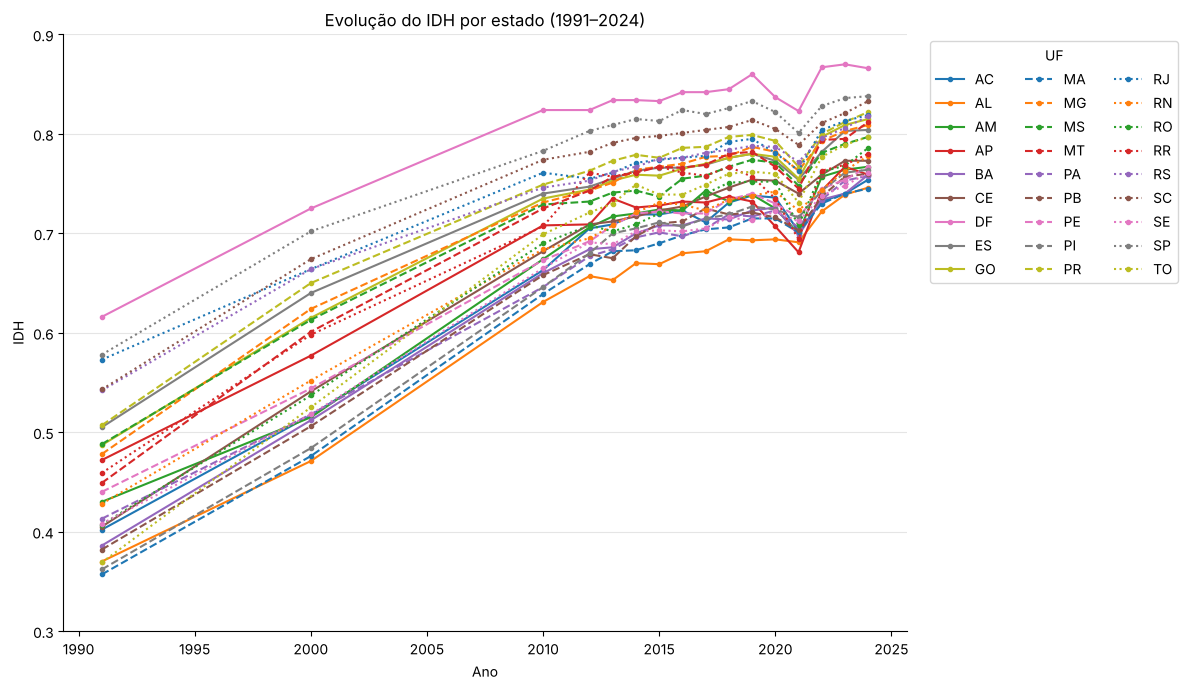

In [14]:
# 27 linhas: combina 9 cores × 3 estilos de linha para cada UF ficar distinguível
cores = plt.cm.tab10.colors[:9]
estilos = ['-', '--', ':']

fig, ax = plt.subplots(figsize=(12, 7))

for i, (sigla, grupo) in enumerate(df_longo.groupby('Sigla')):
    grupo = grupo.sort_values('Ano')
    ax.plot(grupo['Ano'], grupo['IDH'], marker='o', markersize=3, linewidth=1.5,
            color=cores[i % 9], linestyle=estilos[i // 9], label=sigla)

ax.set_title('Evolução do IDH por estado (1991–2024)')
ax.set_xlabel('Ano')
ax.set_ylabel('IDH')
ax.set_ylim(0.3, 0.9)
ax.grid(axis='y', color='#e5e5e5')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(ncol=3, bbox_to_anchor=(1.02, 1), loc='upper left', title='UF')
fig.tight_layout()
fig.savefig('idh_todos_estados.png', dpi=150)
plt.show()

### Extra: destacando MG no meio dos outros estados

Com 27 linhas fica difícil seguir um estado só. Uma alternativa é deixar todos em cinza e destacar os que interessam.

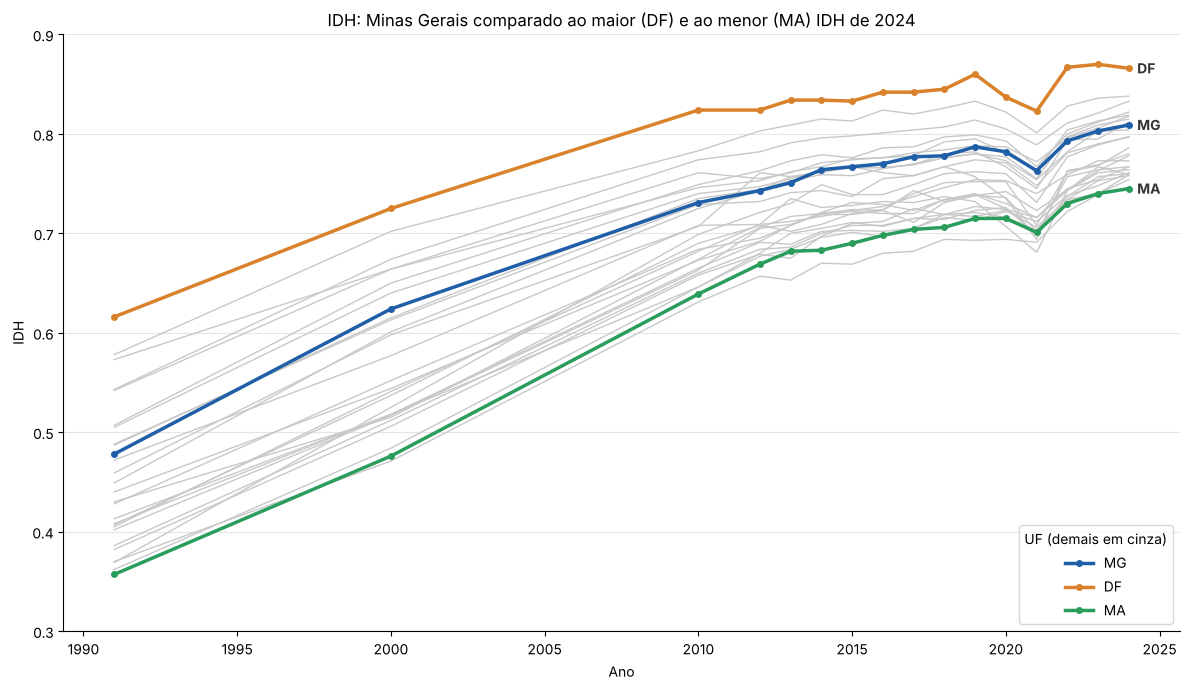

In [15]:
destaques = {'MG': '#1f5fa8', 'DF': '#d9822b', 'MA': '#2a9d5c'}

fig, ax = plt.subplots(figsize=(12, 7))

for sigla, grupo in df_longo.groupby('Sigla'):
    grupo = grupo.sort_values('Ano')
    if sigla in destaques:
        continue
    ax.plot(grupo['Ano'], grupo['IDH'], color='#c8c8c8', linewidth=1)

for sigla, cor in destaques.items():
    grupo = df_longo[df_longo['Sigla'] == sigla].sort_values('Ano')
    ax.plot(grupo['Ano'], grupo['IDH'], color=cor, linewidth=2.5, marker='o', markersize=4, label=sigla)
    ax.annotate(sigla, (2024, grupo['IDH'].iloc[-1]), textcoords='offset points',
                xytext=(6, 0), va='center', fontsize=10, color='#333333', fontweight='bold')

ax.set_title('IDH: Minas Gerais comparado ao maior (DF) e ao menor (MA) IDH de 2024')
ax.set_xlabel('Ano')
ax.set_ylabel('IDH')
ax.set_ylim(0.3, 0.9)
ax.grid(axis='y', color='#e5e5e5')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(loc='lower right', title='UF (demais em cinza)')
fig.tight_layout()
fig.savefig('idh_destaque_mg.png', dpi=150)
plt.show()